# Experiment 10 — Improved Drift Evaluation Methodology

This notebook is arranged in execution order. Run cells from top to bottom in a fresh Google Colab runtime.

**Scope:** Experiment 10 only. The notebook includes dataset validation, image-level splitting, reference-only preprocessing, detector calibration and control evaluation, an initial 10-direction drift test, a sensitivity test with drift scaled to observed variation, a 50-direction validation, and consolidated CSV exports.

**Important limitations:** The 50 directions perturb the same evaluation windows and are not independent dataset replications. The drift is synthetic. All data pools contain the same identities, so this is not an identity-disjoint evaluation. Results should be treated as preliminary, not as proof of real-world performance or publication readiness.

If the dataset file is not already in the Colab session, upload `lfw_vit_embeddings.csv` when prompted by the first code cell.

## 1. Upload the dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving lfw_vit_embeddings.csv to lfw_vit_embeddings.csv


## 2. Load and validate the embedding dataset

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("lfw_vit_embeddings.csv")

assert "identity_label" in df.columns, "Identity label column missing"

feature_cols = [c for c in df.columns if c != "identity_label"]
X = df[feature_cols].to_numpy(dtype=np.float32)

print("Dataset shape:", df.shape)
print("Images:", len(df))
print("Embedding dimensions:", X.shape[1])
print("Identities:", df["identity_label"].nunique())
print("Missing values:", df.isna().sum().sum())
print("All features finite:", np.isfinite(X).all())
print("Duplicate complete rows:", df.duplicated().sum())

Dataset shape: (3023, 769)
Images: 3023
Embedding dimensions: 768
Identities: 62
Missing values: 0
All features finite: True
Duplicate complete rows: 0


## 3. Split into reference, calibration, control, and evaluation pools

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(df))

# First: 40% reference, 60% remaining
reference_idx, remaining_idx = train_test_split(
    all_indices,
    test_size=0.60,
    random_state=2030,
    shuffle=True
)

# Split remaining 60% into three equal pools (20% each overall)
calibration_idx, remaining_idx = train_test_split(
    remaining_idx,
    test_size=2/3,
    random_state=2031,
    shuffle=True
)

control_idx, evaluation_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    random_state=2032,
    shuffle=True
)

# Extract embedding arrays
X_reference = X[reference_idx]
X_calibration = X[calibration_idx]
X_control = X[control_idx]
X_evaluation = X[evaluation_idx]

# Validate sizes and disjointness
pools = {
    "Reference": reference_idx,
    "Calibration": calibration_idx,
    "Control": control_idx,
    "Evaluation": evaluation_idx
}

for name, indices in pools.items():
    print(
        f"{name}: {len(indices)} images, "
        f"{df.iloc[indices]['identity_label'].nunique()} identities"
    )

names = list(pools.keys())
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        overlap = len(
            set(pools[names[i]]) & set(pools[names[j]])
        )
        print(f"{names[i]} / {names[j]} overlap: {overlap}")

print("Total images assigned:", sum(len(v) for v in pools.values()))

Reference: 1209 images, 62 identities
Calibration: 604 images, 62 identities
Control: 605 images, 62 identities
Evaluation: 605 images, 62 identities
Reference / Calibration overlap: 0
Reference / Control overlap: 0
Reference / Evaluation overlap: 0
Calibration / Control overlap: 0
Calibration / Evaluation overlap: 0
Control / Evaluation overlap: 0
Total images assigned: 3023


## 4. Fit preprocessing on reference data only

In [ ]:
import numpy as np

# Fit preprocessing on reference data only
reference_mean = X_reference.mean(axis=0)
reference_std = X_reference.std(axis=0)

# Avoid division by zero for constant features
reference_std[reference_std == 0] = 1.0

# Apply the same reference statistics to every pool
Z_reference = (X_reference - reference_mean) / reference_std
Z_calibration = (X_calibration - reference_mean) / reference_std
Z_control = (X_control - reference_mean) / reference_std
Z_evaluation = (X_evaluation - reference_mean) / reference_std

print("Reference shape:", Z_reference.shape)
print("Calibration shape:", Z_calibration.shape)
print("Control shape:", Z_control.shape)
print("Evaluation shape:", Z_evaluation.shape)

print("Reference mean:", round(float(Z_reference.mean()), 4))
print("Reference std:", round(float(Z_reference.std()), 4))

print("All pools finite:", all([
    np.isfinite(Z_reference).all(),
    np.isfinite(Z_calibration).all(),
    np.isfinite(Z_control).all(),
    np.isfinite(Z_evaluation).all()
]))

Reference shape: (1209, 768)
Calibration shape: (604, 768)
Control shape: (605, 768)
Evaluation shape: (605, 768)
Reference mean: -0.0
Reference std: 1.0
All pools finite: True


## 5. Fit detectors, calibrate thresholds, and evaluate no-shift control

In [ ]:

import numpy as np
import pandas as pd

# Configuration
WINDOW_SIZE = 20
CALIBRATION_QUANTILE = 0.95
RIDGE_VALUES = [0.001, 0.01, 0.1]


# Generate non-overlapping windows
def make_windows(data, window_size, seed):
    rng = np.random.default_rng(seed)
    shuffled = data[rng.permutation(len(data))]

    n_windows = len(shuffled) // window_size
    usable = shuffled[:n_windows * window_size]

    return usable.reshape(
        n_windows, window_size, data.shape[1]
    ).mean(axis=1)


# Euclidean distance scores
def euclidean_scores(window_means, center):
    return np.linalg.norm(window_means - center, axis=1)


# Fit regularised Mahalanobis detector
def fit_mahalanobis(reference_data, ridge):
    center = reference_data.mean(axis=0)
    covariance = np.cov(reference_data, rowvar=False)

    regularised = covariance + ridge * np.eye(
        covariance.shape[0]
    )

    inverse_covariance = np.linalg.pinv(regularised)

    return center, inverse_covariance


# Mahalanobis distance scores
def mahalanobis_scores(
    window_means, center, inverse_covariance
):
    delta = window_means - center

    squared = np.einsum(
        "ij,jk,ik->i",
        delta,
        inverse_covariance,
        delta
    )

    return np.sqrt(np.maximum(squared, 0))


# Calculate threshold from calibration scores
def get_threshold(
    scores,
    quantile=CALIBRATION_QUANTILE
):
    return float(
        np.quantile(scores, quantile, method="higher")
    )


# Generate separate windows for each data pool
W_calibration = make_windows(
    Z_calibration, WINDOW_SIZE, seed=3010
)

W_control = make_windows(
    Z_control, WINDOW_SIZE, seed=3011
)

W_evaluation = make_windows(
    Z_evaluation, WINDOW_SIZE, seed=3012
)

print("Calibration windows:", len(W_calibration))
print("Control windows:", len(W_control))
print("Evaluation windows:", len(W_evaluation))


# Fit detector configurations using reference data
# Calibrate thresholds using calibration data
detectors = {}

# Euclidean detector
reference_center = Z_reference.mean(axis=0)

euclidean_cal_scores = euclidean_scores(
    W_calibration,
    reference_center
)

detectors[("Euclidean", None)] = {
    "center": reference_center,
    "inverse_covariance": None,
    "threshold": get_threshold(
        euclidean_cal_scores,
        quantile=CALIBRATION_QUANTILE
    )
}


# Mahalanobis detectors
for ridge in RIDGE_VALUES:

    center, inverse_covariance = fit_mahalanobis(
        Z_reference,
        ridge
    )

    calibration_scores = mahalanobis_scores(
        W_calibration,
        center,
        inverse_covariance
    )

    detectors[("Mahalanobis", ridge)] = {
        "center": center,
        "inverse_covariance": inverse_covariance,
        "threshold": get_threshold(
            calibration_scores,
            quantile=CALIBRATION_QUANTILE
        )
    }


# Evaluate thresholds on the independent no-shift control pool
control_rows = []

for (name, ridge), model in detectors.items():

    if name == "Euclidean":
        scores = euclidean_scores(
            W_control,
            model["center"]
        )
    else:
        scores = mahalanobis_scores(
            W_control,
            model["center"],
            model["inverse_covariance"]
        )

    alarms = scores > model["threshold"]

    control_rows.append({
        "detector": name,
        "ridge": ridge,
        "threshold": model["threshold"],
        "control_windows": len(scores),
        "control_alarms": int(alarms.sum()),
        "control_alarm_rate": float(alarms.mean())
    })


control_results = pd.DataFrame(control_rows)

print("\nThreshold calibration and control results:")
display(control_results.round(4))


Calibration windows: 30
Control windows: 30
Evaluation windows: 30

Threshold calibration and control results:


,detector,ridge,threshold,control_windows,control_alarms,control_alarm_rate
0,Euclidean,NaN,7.5478,30,3,0.1000
1,Mahalanobis,0.001,14.0490,30,1,0.0333
2,Mahalanobis,0.010,11.1010,30,1,0.0333
3,Mahalanobis,0.100,6.9832,30,0,0.0000


## 6. Initial controlled drift trials (10 directions)

In [ ]:

import numpy as np
import pandas as pd

# Experiment 10: controlled drift trials
DRIFT_STRENGTHS = [0.0, 0.05, 0.10, 0.20, 0.35]
N_DIRECTIONS = 10
DRIFT_START = len(W_evaluation) // 2
REQUIRED_CONSECUTIVE_ALARMS = 2

# Generate reproducible random drift directions
rng = np.random.default_rng(2033)

directions = rng.normal(
    size=(N_DIRECTIONS, Z_evaluation.shape[1])
)
directions /= np.linalg.norm(
    directions, axis=1, keepdims=True
)

trial_rows = []

for strength in DRIFT_STRENGTHS:
    for direction_id, direction in enumerate(directions):

        shifted_windows = W_evaluation.copy()

        # Apply drift only after the specified drift-start window
        if strength > 0:
            shifted_windows[DRIFT_START:] += strength * direction

        for (name, ridge), model in detectors.items():

            if name == "Euclidean":
                scores = euclidean_scores(
                    shifted_windows,
                    model["center"]
                )
            else:
                scores = mahalanobis_scores(
                    shifted_windows,
                    model["center"],
                    model["inverse_covariance"]
                )

            alarms = scores > model["threshold"]
            post_alarms = alarms[DRIFT_START:]

            pre_alarm_rate = float(
                alarms[:DRIFT_START].mean()
            )
            post_alarm_rate = float(post_alarms.mean())

            positions = np.flatnonzero(post_alarms)

            first_alarm_delay = (
                int(positions[0])
                if len(positions) > 0
                else np.nan
            )

            # Require two consecutive post-drift alarms
            consecutive_start = np.nan

            for i in range(
                len(post_alarms) - REQUIRED_CONSECUTIVE_ALARMS + 1
            ):
                segment = post_alarms[
                    i:i + REQUIRED_CONSECUTIVE_ALARMS
                ]

                if segment.all():
                    consecutive_start = i
                    break

            strict_detected = int(
                not np.isnan(consecutive_start)
            )

            strict_delay = (
                int(consecutive_start)
                if strict_detected
                else np.nan
            )

            trial_rows.append({
                "drift_strength": strength,
                "direction_id": direction_id,
                "detector": name,
                "ridge": ridge,
                "evaluation_windows": len(shifted_windows),
                "drift_start_window": DRIFT_START,
                "pre_shift_alarm_rate": pre_alarm_rate,
                "post_shift_alarm_rate": post_alarm_rate,
                "any_post_alarm": int(len(positions) > 0),
                "first_alarm_delay_windows": first_alarm_delay,
                "detected_2_consecutive": strict_detected,
                "delay_2_consecutive_windows": strict_delay
            })

trial_df = pd.DataFrame(trial_rows)

print("Trial generation completed.")
print("Total trial rows:", len(trial_df))
print("Expected trial rows:",
      len(DRIFT_STRENGTHS) * N_DIRECTIONS * len(detectors))

display(trial_df.head(10))


Trial generation completed.
Total trial rows: 200
Expected trial rows: 200


,drift_strength,direction_id,detector,ridge,evaluation_windows,drift_start_window,pre_shift_alarm_rate,post_shift_alarm_rate,any_post_alarm,first_alarm_delay_windows,detected_2_consecutive,delay_2_consecutive_windows
0,0.0,0,Euclidean,NaN,30,15,0.0,0.066667,1,9.0,0,NaN
1,0.0,0,Mahalanobis,0.001,30,15,0.0,0.000000,0,NaN,0,NaN
2,0.0,0,Mahalanobis,0.010,30,15,0.0,0.000000,0,NaN,0,NaN
3,0.0,0,Mahalanobis,0.100,30,15,0.0,0.000000,0,NaN,0,NaN
4,0.0,1,Euclidean,NaN,30,15,0.0,0.066667,1,9.0,0,NaN
5,0.0,1,Mahalanobis,0.001,30,15,0.0,0.000000,0,NaN,0,NaN
6,0.0,1,Mahalanobis,0.010,30,15,0.0,0.000000,0,NaN,0,NaN
7,0.0,1,Mahalanobis,0.100,30,15,0.0,0.000000,0,NaN,0,NaN
8,0.0,2,Euclidean,NaN,30,15,0.0,0.066667,1,9.0,0,NaN
9,0.0,2,Mahalanobis,0.001,30,15,0.0,0.000000,0,NaN,0,NaN


## 7. Summarise initial drift-trial results

In [ ]:

# Experiment 10: summarize drift detection results

summary_df = (
    trial_df
    .groupby(
        ["drift_strength", "detector", "ridge"],
        dropna=False
    )
    .agg(
        directions=("direction_id", "nunique"),
        any_alarm_pct=(
            "any_post_alarm",
            lambda x: 100 * x.mean()
        ),
        strict_detection_pct=(
            "detected_2_consecutive",
            lambda x: 100 * x.mean()
        ),
        mean_strict_delay=(
            "delay_2_consecutive_windows",
            "mean"
        ),
        post_alarm_rate=(
            "post_shift_alarm_rate",
            "mean"
        )
    )
    .reset_index()
)

summary_df["post_alarm_pct"] = (
    100 * summary_df["post_alarm_rate"]
)

print("Summary rows:", len(summary_df))

display(
    summary_df[
        [
            "drift_strength",
            "detector",
            "ridge",
            "directions",
            "any_alarm_pct",
            "strict_detection_pct",
            "mean_strict_delay",
            "post_alarm_pct"
        ]
    ].round(3)
)


Summary rows: 20


,drift_strength,detector,ridge,directions,any_alarm_pct,strict_detection_pct,mean_strict_delay,post_alarm_pct
0,0.00,Euclidean,NaN,10,100.0,0.0,NaN,6.667
1,0.00,Mahalanobis,0.001,10,0.0,0.0,NaN,0.000
2,0.00,Mahalanobis,0.010,10,0.0,0.0,NaN,0.000
3,0.00,Mahalanobis,0.100,10,0.0,0.0,NaN,0.000
4,0.05,Euclidean,NaN,10,100.0,0.0,NaN,6.667
5,0.05,Mahalanobis,0.001,10,0.0,0.0,NaN,0.000
6,0.05,Mahalanobis,0.010,10,0.0,0.0,NaN,0.000
7,0.05,Mahalanobis,0.100,10,0.0,0.0,NaN,0.000
8,0.10,Euclidean,NaN,10,100.0,0.0,NaN,6.667
9,0.10,Mahalanobis,0.001,10,0.0,0.0,NaN,0.000


## 8. Sensitivity test using drift strengths scaled to observed natural variation

In [ ]:

# Experiment 10: sensitivity test with stronger injected drift
# Existing detector thresholds remain unchanged.

# Calculate the scale from the first half of the evaluation windows.
baseline_mean = W_evaluation[:DRIFT_START].mean(axis=0)
natural_distances = np.linalg.norm(
    W_evaluation[:DRIFT_START] - baseline_mean,
    axis=1
)
NATURAL_VARIATION = float(np.median(natural_distances))
print(f"Median natural variation: {NATURAL_VARIATION:.6f}")

TEST_DRIFT_STRENGTHS = [
    0.0,
    0.25 * NATURAL_VARIATION,
    0.50 * NATURAL_VARIATION,
    1.00 * NATURAL_VARIATION,
    1.50 * NATURAL_VARIATION,
    2.00 * NATURAL_VARIATION
]

sensitivity_rows = []

for strength in TEST_DRIFT_STRENGTHS:
    for direction_id, direction in enumerate(directions):

        shifted_windows = W_evaluation.copy()

        if strength > 0:
            shifted_windows[DRIFT_START:] += strength * direction

        for (name, ridge), model in detectors.items():

            if name == "Euclidean":
                scores = euclidean_scores(
                    shifted_windows,
                    model["center"]
                )
            else:
                scores = mahalanobis_scores(
                    shifted_windows,
                    model["center"],
                    model["inverse_covariance"]
                )

            alarms = scores > model["threshold"]
            post_alarms = alarms[DRIFT_START:]

            consecutive_detected = any(
                post_alarms[i] and post_alarms[i + 1]
                for i in range(len(post_alarms) - 1)
            )

            sensitivity_rows.append({
                "drift_strength": strength,
                "drift_multiplier": strength / NATURAL_VARIATION,
                "direction_id": direction_id,
                "detector": name,
                "ridge": ridge,
                "post_alarm_rate": float(post_alarms.mean()),
                "any_post_alarm": int(post_alarms.any()),
                "detected_2_consecutive": int(consecutive_detected)
            })

sensitivity_df = pd.DataFrame(sensitivity_rows)

sensitivity_summary = (
    sensitivity_df
    .groupby(
        ["drift_multiplier", "detector", "ridge"],
        dropna=False
    )
    .agg(
        directions=("direction_id", "nunique"),
        any_alarm_pct=("any_post_alarm", lambda x: 100 * x.mean()),
        strict_detection_pct=(
            "detected_2_consecutive",
            lambda x: 100 * x.mean()
        ),
        mean_post_alarm_rate=("post_alarm_rate", "mean")
    )
    .reset_index()
)

sensitivity_summary["post_alarm_pct"] = (
    100 * sensitivity_summary["mean_post_alarm_rate"]
)

print("Sensitivity-test rows:", len(sensitivity_df))
print("Summary rows:", len(sensitivity_summary))

display(sensitivity_summary.round(3))


Median natural variation: 6.114337
Sensitivity-test rows: 240
Summary rows: 24


,drift_multiplier,detector,ridge,directions,any_alarm_pct,strict_detection_pct,mean_post_alarm_rate,post_alarm_pct
0,0.00,Euclidean,NaN,10,100.0,0.0,0.067,6.667
1,0.00,Mahalanobis,0.001,10,0.0,0.0,0.000,0.000
2,0.00,Mahalanobis,0.010,10,0.0,0.0,0.000,0.000
3,0.00,Mahalanobis,0.100,10,0.0,0.0,0.000,0.000
4,0.25,Euclidean,NaN,10,100.0,0.0,0.067,6.667
5,0.25,Mahalanobis,0.001,10,100.0,100.0,0.587,58.667
6,0.25,Mahalanobis,0.010,10,100.0,100.0,0.453,45.333
7,0.25,Mahalanobis,0.100,10,100.0,100.0,0.160,16.000
8,0.50,Euclidean,NaN,10,100.0,0.0,0.127,12.667
9,0.50,Mahalanobis,0.001,10,100.0,100.0,1.000,100.000


## 9. Robustness validation with 50 directions

In [ ]:

# Experiment 10: robustness validation with 50 drift directions

N_VALIDATION_DIRECTIONS = 50
VALIDATION_MULTIPLIERS = [0.0, 0.25, 0.5, 1.0]

validation_rng = np.random.default_rng(2041)

validation_directions = validation_rng.normal(
    size=(N_VALIDATION_DIRECTIONS, Z_evaluation.shape[1])
)
validation_directions /= np.linalg.norm(
    validation_directions, axis=1, keepdims=True
)

validation_rows = []

for multiplier in VALIDATION_MULTIPLIERS:
    strength = multiplier * NATURAL_VARIATION

    for direction_id, direction in enumerate(validation_directions):
        shifted_windows = W_evaluation.copy()

        if strength > 0:
            shifted_windows[DRIFT_START:] += (
                strength * direction
            )

        for (name, ridge), model in detectors.items():
            if name == "Euclidean":
                scores = euclidean_scores(
                    shifted_windows, model["center"]
                )
            else:
                scores = mahalanobis_scores(
                    shifted_windows,
                    model["center"],
                    model["inverse_covariance"]
                )

            post_alarms = (
                scores[DRIFT_START:] > model["threshold"]
            )

            strict_detected = any(
                post_alarms[i] and post_alarms[i + 1]
                for i in range(len(post_alarms) - 1)
            )

            validation_rows.append({
                "drift_multiplier": multiplier,
                "direction_id": direction_id,
                "detector": name,
                "ridge": ridge,
                "any_post_alarm": int(post_alarms.any()),
                "strict_detection": int(strict_detected),
                "post_alarm_rate": float(post_alarms.mean())
            })

validation_df = pd.DataFrame(validation_rows)

validation_summary = (
    validation_df
    .groupby(
        ["drift_multiplier", "detector", "ridge"],
        dropna=False
    )
    .agg(
        directions=("direction_id", "nunique"),
        any_alarm_pct=(
            "any_post_alarm", lambda x: 100 * x.mean()
        ),
        strict_detection_pct=(
            "strict_detection", lambda x: 100 * x.mean()
        ),
        post_alarm_pct=(
            "post_alarm_rate", lambda x: 100 * x.mean()
        )
    )
    .reset_index()
)

print("Validation trial rows:", len(validation_df))
display(validation_summary.round(2))


Validation trial rows: 800


,drift_multiplier,detector,ridge,directions,any_alarm_pct,strict_detection_pct,post_alarm_pct
0,0.00,Euclidean,NaN,50,100.0,0.0,6.67
1,0.00,Mahalanobis,0.00,50,0.0,0.0,0.00
2,0.00,Mahalanobis,0.01,50,0.0,0.0,0.00
3,0.00,Mahalanobis,0.10,50,0.0,0.0,0.00
4,0.25,Euclidean,NaN,50,100.0,0.0,6.67
5,0.25,Mahalanobis,0.00,50,100.0,100.0,66.27
6,0.25,Mahalanobis,0.01,50,100.0,100.0,49.07
7,0.25,Mahalanobis,0.10,50,100.0,100.0,17.73
8,0.50,Euclidean,NaN,50,100.0,0.0,12.93
9,0.50,Mahalanobis,0.00,50,100.0,100.0,100.00


In [12]:

# Experiment 10 — validation setup audit
import numpy as np
import pandas as pd

print("Evaluation windows:", len(W_evaluation))
print("Window shape:", W_evaluation.shape)
print("Drift start index:", DRIFT_START)
print("Pre-shift windows:", DRIFT_START)
print("Post-shift windows:", len(W_evaluation) - DRIFT_START)
print("Validation directions:", N_VALIDATION_DIRECTIONS)
print("Validation multipliers:", VALIDATION_MULTIPLIERS)
print("Natural variation:", NATURAL_VARIATION)

assert len(W_evaluation) > DRIFT_START
assert len(validation_directions) == N_VALIDATION_DIRECTIONS
assert np.isfinite(W_evaluation).all()
assert np.isfinite(validation_directions).all()

print("\nAudit passed: arrays and validation settings are present.")


Evaluation windows: 30
Window shape: (30, 768)
Drift start index: 15
Pre-shift windows: 15
Post-shift windows: 15
Validation directions: 50
Validation multipliers: [0.0, 0.25, 0.5, 1.0]
Natural variation: 6.114336967468262

Audit passed: arrays and validation settings are present.


## 10. Consolidated results and CSV exports

In [ ]:
# Experiment 10: final consolidated results and CSV exports

print("=== CONTROL FALSE-ALARM RESULTS ===")
display(
    control_results[
        [
            "detector", "ridge", "threshold",
            "control_windows", "control_alarms", "control_alarm_rate"
        ]
    ].round(4)
)

print("\n=== SENSITIVITY TEST: 10 DIRECTIONS ===")
display(
    sensitivity_summary[
        [
            "drift_multiplier", "detector", "ridge", "directions",
            "any_alarm_pct", "strict_detection_pct", "post_alarm_pct"
        ]
    ].round(3)
)

print("\n=== VALIDATION TEST: 50 DIRECTIONS ===")
display(
    validation_summary[
        [
            "drift_multiplier", "detector", "ridge", "directions",
            "any_alarm_pct", "strict_detection_pct", "post_alarm_pct"
        ]
    ].round(3)
)

control_results.to_csv("experiment10_control_results.csv", index=False)
sensitivity_summary.to_csv("experiment10_sensitivity_results.csv", index=False)
validation_summary.to_csv("experiment10_50_direction_validation.csv", index=False)

print("\nExperiment 10 results consolidated successfully.")
print("Saved three CSV files in the current Colab session.")


=== CONTROL FALSE-ALARM RESULTS ===


,detector,ridge,threshold,control_windows,control_alarms,control_alarm_rate
0,Euclidean,NaN,7.5478,30,3,0.1000
1,Mahalanobis,0.001,14.0490,30,1,0.0333
2,Mahalanobis,0.010,11.1010,30,1,0.0333
3,Mahalanobis,0.100,6.9832,30,0,0.0000



=== SENSITIVITY TEST: 10 DIRECTIONS ===


,drift_multiplier,detector,ridge,directions,any_alarm_pct,strict_detection_pct,post_alarm_pct
0,0.00,Euclidean,NaN,10,100.0,0.0,6.667
1,0.00,Mahalanobis,0.001,10,0.0,0.0,0.000
2,0.00,Mahalanobis,0.010,10,0.0,0.0,0.000
3,0.00,Mahalanobis,0.100,10,0.0,0.0,0.000
4,0.25,Euclidean,NaN,10,100.0,0.0,6.667
5,0.25,Mahalanobis,0.001,10,100.0,100.0,58.667
6,0.25,Mahalanobis,0.010,10,100.0,100.0,45.333
7,0.25,Mahalanobis,0.100,10,100.0,100.0,16.000
8,0.50,Euclidean,NaN,10,100.0,0.0,12.667
9,0.50,Mahalanobis,0.001,10,100.0,100.0,100.000



=== VALIDATION TEST: 50 DIRECTIONS ===


,drift_multiplier,detector,ridge,directions,any_alarm_pct,strict_detection_pct,post_alarm_pct
0,0.00,Euclidean,NaN,50,100.0,0.0,6.667
1,0.00,Mahalanobis,0.001,50,0.0,0.0,0.000
2,0.00,Mahalanobis,0.010,50,0.0,0.0,0.000
3,0.00,Mahalanobis,0.100,50,0.0,0.0,0.000
4,0.25,Euclidean,NaN,50,100.0,0.0,6.667
5,0.25,Mahalanobis,0.001,50,100.0,100.0,66.267
6,0.25,Mahalanobis,0.010,50,100.0,100.0,49.067
7,0.25,Mahalanobis,0.100,50,100.0,100.0,17.733
8,0.50,Euclidean,NaN,50,100.0,0.0,12.933
9,0.50,Mahalanobis,0.001,50,100.0,100.0,100.000



Experiment 10 results consolidated successfully.
Saved three CSV files in the current Colab session.


## 11. Optional: download the result CSVs

In [ ]:
# Optional: download the three CSV result files to your computer
# Run this cell only after the consolidation cell has completed.

from google.colab import files

files.download("experiment10_control_results.csv")
files.download("experiment10_sensitivity_results.csv")
files.download("experiment10_50_direction_validation.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:

# Experiment 10 — independent resampling-based validation
# This is a supplementary test; baseline results remain unchanged.

import numpy as np
import pandas as pd

N_RESAMPLING_TRIALS = 100
RESAMPLE_MULTIPLIERS = [0.0, 0.25, 0.5, 1.0]
SHIFT_START_FRACTION = 0.5

rng = np.random.default_rng(2051)
resampling_rows = []

# Sample from the existing evaluation embeddings.
# Each trial creates new windows by resampling with replacement.
for trial_id in range(N_RESAMPLING_TRIALS):
    sampled_indices = rng.integers(
        0, len(Z_evaluation), size=len(Z_evaluation)
    )
    sampled_data = Z_evaluation[sampled_indices]

    trial_windows = make_windows(
        sampled_data, WINDOW_SIZE, seed=30000 + trial_id
    )

    split_at = int(len(trial_windows) * SHIFT_START_FRACTION)
    if split_at == 0 or split_at == len(trial_windows):
        raise ValueError("Not enough windows for pre/post split.")

    # Use the median natural variation scale from the baseline.
    for multiplier in RESAMPLE_MULTIPLIERS:
        shifted = trial_windows.copy()
        strength = multiplier * NATURAL_VARIATION

        # New random unit direction for each trial and multiplier.
        direction = rng.normal(size=Z_evaluation.shape[1])
        direction /= np.linalg.norm(direction)

        if strength > 0:
            shifted[split_at:] += strength * direction

        for (name, ridge), model in detectors.items():
            if name == "Euclidean":
                scores = euclidean_scores(shifted, model["center"])
            else:
                scores = mahalanobis_scores(
                    shifted, model["center"],
                    model["inverse_covariance"]
                )

            alarms = scores[split_at:] > model["threshold"]
            strict = any(
                alarms[i] and alarms[i + 1]
                for i in range(len(alarms) - 1)
            )

            resampling_rows.append({
                "trial_id": trial_id,
                "drift_multiplier": multiplier,
                "detector": name,
                "ridge": ridge,
                "any_post_alarm": int(alarms.any()),
                "strict_detection": int(strict),
                "post_alarm_rate": float(alarms.mean())
            })

resampling_df = pd.DataFrame(resampling_rows)

resampling_summary = (
    resampling_df
    .groupby(["drift_multiplier", "detector", "ridge"], dropna=False)
    .agg(
        trials=("trial_id", "nunique"),
        any_alarm_pct=("any_post_alarm", lambda x: 100 * x.mean()),
        strict_detection_pct=("strict_detection", lambda x: 100 * x.mean()),
        mean_post_alarm_pct=("post_alarm_rate", lambda x: 100 * x.mean()),
        detection_rate_sd=("strict_detection", "std")
    )
    .reset_index()
)

display(resampling_summary.round(3))

resampling_df.to_csv(
    "experiment10_resampling_trials.csv", index=False
)
resampling_summary.to_csv(
    "experiment10_resampling_summary.csv", index=False
)

print("Saved supplementary resampling validation CSVs.")
print("Important: resampling trials are not independent external datasets.")


,drift_multiplier,detector,ridge,trials,any_alarm_pct,strict_detection_pct,mean_post_alarm_pct,detection_rate_sd
0,0.00,Euclidean,NaN,100,58.0,3.0,5.133,0.171
1,0.00,Mahalanobis,0.001,100,25.0,0.0,1.867,0.000
2,0.00,Mahalanobis,0.010,100,30.0,0.0,2.400,0.000
3,0.00,Mahalanobis,0.100,100,21.0,0.0,1.467,0.000
4,0.25,Euclidean,NaN,100,67.0,4.0,6.400,0.197
5,0.25,Mahalanobis,0.001,100,100.0,100.0,68.867,0.000
6,0.25,Mahalanobis,0.010,100,100.0,96.0,52.733,0.197
7,0.25,Mahalanobis,0.100,100,96.0,41.0,21.533,0.494
8,0.50,Euclidean,NaN,100,99.0,33.0,17.867,0.473
9,0.50,Mahalanobis,0.001,100,100.0,100.0,100.000,0.000


Saved supplementary resampling validation CSVs.
Important: resampling trials are not independent external datasets.


In [14]:

# Experiment 10 — calibration threshold audit
import numpy as np
import pandas as pd

print("Calibration windows:", len(W_calibration))
print("Calibration quantile:", CALIBRATION_QUANTILE)

threshold_audit = []

for (name, ridge), model in detectors.items():
    if name == "Euclidean":
        scores = euclidean_scores(
            W_calibration, model["center"]
        )
    else:
        scores = mahalanobis_scores(
            W_calibration,
            model["center"],
            model["inverse_covariance"]
        )

    threshold = model["threshold"]

    threshold_audit.append({
        "detector": name,
        "ridge": ridge,
        "calibration_windows": len(scores),
        "threshold": threshold,
        "scores_above_threshold": int((scores > threshold).sum()),
        "scores_equal_threshold": int((scores == threshold).sum()),
        "empirical_alarm_rate": float((scores > threshold).mean())
    })

threshold_audit_df = pd.DataFrame(threshold_audit)
display(threshold_audit_df.round(4))

threshold_audit_df.to_csv(
    "experiment10_threshold_audit.csv",
    index=False
)

print("Saved: experiment10_threshold_audit.csv")


Calibration windows: 30
Calibration quantile: 0.95


,detector,ridge,calibration_windows,threshold,scores_above_threshold,scores_equal_threshold,empirical_alarm_rate
0,Euclidean,NaN,30,7.5478,1,1,0.0333
1,Mahalanobis,0.001,30,14.0490,1,1,0.0333
2,Mahalanobis,0.010,30,11.1010,1,1,0.0333
3,Mahalanobis,0.100,30,6.9832,1,1,0.0333


Saved: experiment10_threshold_audit.csv


In [15]:

# Experiment 10 — inspect available data pools
import pandas as pd

pool_report = pd.DataFrame([
    {
        "pool": "Reference",
        "images": len(Z_reference)
    },
    {
        "pool": "Calibration",
        "images": len(Z_calibration)
    },
    {
        "pool": "Control",
        "images": len(Z_control)
    },
    {
        "pool": "Evaluation",
        "images": len(Z_evaluation)
    }
])

pool_report["possible_nonoverlapping_windows"] = (
    pool_report["images"] // WINDOW_SIZE
)

display(pool_report)

print("Original dataset rows:", len(df))
print("Embedding dimensions:", X.shape[1])
print("Window size:", WINDOW_SIZE)
print("Baseline results remain unchanged.")


,pool,images,possible_nonoverlapping_windows
0,Reference,1209,60
1,Calibration,604,30
2,Control,605,30
3,Evaluation,605,30


Original dataset rows: 3023
Embedding dimensions: 768
Window size: 20
Baseline results remain unchanged.


In [16]:

# Experiment 10 — threshold stability across repeated splits
import numpy as np
import pandas as pd

N_SPLITS = 100
WINDOW_SIZE = 20
rng = np.random.default_rng(2061)

threshold_rows = []

for split_id in range(N_SPLITS):
    permutation = rng.permutation(len(Z_calibration))
    selected = Z_calibration[permutation]

    # Use half the calibration pool for this split's threshold estimate.
    n_images = (len(selected) // 2 // WINDOW_SIZE) * WINDOW_SIZE
    calibration_sample = selected[:n_images]

    windows = calibration_sample.reshape(
        -1, WINDOW_SIZE, calibration_sample.shape[1]
    ).mean(axis=1)

    for (name, ridge), model in detectors.items():
        if name == "Euclidean":
            scores = euclidean_scores(windows, model["center"])
        else:
            scores = mahalanobis_scores(
                windows,
                model["center"],
                model["inverse_covariance"]
            )

        threshold_rows.append({
            "split_id": split_id,
            "detector": name,
            "ridge": ridge,
            "n_calibration_windows": len(scores),
            "threshold": float(
                np.quantile(scores, CALIBRATION_QUANTILE, method="higher")
            )
        })

threshold_stability_df = pd.DataFrame(threshold_rows)

threshold_stability_summary = (
    threshold_stability_df
    .groupby(["detector", "ridge"], dropna=False)
    .agg(
        splits=("split_id", "nunique"),
        mean_threshold=("threshold", "mean"),
        std_threshold=("threshold", "std"),
        min_threshold=("threshold", "min"),
        median_threshold=("threshold", "median"),
        max_threshold=("threshold", "max")
    )
    .reset_index()
)

display(threshold_stability_summary.round(4))

threshold_stability_df.to_csv(
    "experiment10_threshold_stability_trials.csv", index=False
)
threshold_stability_summary.to_csv(
    "experiment10_threshold_stability_summary.csv", index=False
)

print("Saved threshold stability results.")
print("Note: these are repeated splits of the same calibration pool.")


,detector,ridge,splits,mean_threshold,std_threshold,min_threshold,median_threshold,max_threshold
0,Euclidean,NaN,100,7.6404,0.6270,6.5386,7.6076,9.7583
1,Mahalanobis,0.001,100,14.1166,0.7949,12.3555,14.0979,16.9881
2,Mahalanobis,0.010,100,11.1965,0.6069,9.5821,11.1178,13.2639
3,Mahalanobis,0.100,100,6.8254,0.3356,6.0422,6.7742,7.8473


Saved threshold stability results.
Note: these are repeated splits of the same calibration pool.


In [17]:

# Experiment 10 — final artifact consistency check
from pathlib import Path
import pandas as pd

required_files = [
    "experiment10_control_results.csv",
    "experiment10_sensitivity_results.csv",
    "experiment10_50_direction_validation.csv",
    "experiment10_combined_comparison.csv",
    "experiment10_resampling_trials.csv",
    "experiment10_resampling_summary.csv",
    "experiment10_threshold_audit.csv",
    "experiment10_threshold_stability_trials.csv",
    "experiment10_threshold_stability_summary.csv",
]

rows = []

for filename in required_files:
    path = Path(filename)
    rows.append({
        "file": filename,
        "exists": path.exists(),
        "size_bytes": path.stat().st_size if path.exists() else None
    })

artifact_check = pd.DataFrame(rows)
display(artifact_check)

missing = artifact_check.loc[~artifact_check["exists"], "file"].tolist()

if missing:
    print("\nMissing files:", missing)
else:
    print("\nAll nine expected CSV artifacts are present.")


,file,exists,size_bytes
0,experiment10_control_results.csv,True,279.0
1,experiment10_sensitivity_results.csv,True,1302.0
2,experiment10_50_direction_validation.csv,True,794.0
3,experiment10_combined_comparison.csv,False,NaN
4,experiment10_resampling_trials.csv,True,56606.0
5,experiment10_resampling_summary.csv,True,1013.0
6,experiment10_threshold_audit.csv,True,356.0
7,experiment10_threshold_stability_trials.csv,True,15962.0
8,experiment10_threshold_stability_summary.csv,True,545.0



Missing files: ['experiment10_combined_comparison.csv']


In [18]:

# Recreate the combined comparison CSV
import pandas as pd
from pathlib import Path

sensitivity = pd.read_csv("experiment10_sensitivity_results.csv")
validation = pd.read_csv("experiment10_50_direction_validation.csv")
control = pd.read_csv("experiment10_control_results.csv")

print("Sensitivity columns:", sensitivity.columns.tolist())
print("Validation columns:", validation.columns.tolist())
print("Control columns:", control.columns.tolist())


Sensitivity columns: ['drift_multiplier', 'detector', 'ridge', 'directions', 'any_alarm_pct', 'strict_detection_pct', 'mean_post_alarm_rate', 'post_alarm_pct']
Validation columns: ['drift_multiplier', 'detector', 'ridge', 'directions', 'any_alarm_pct', 'strict_detection_pct', 'post_alarm_pct']
Control columns: ['detector', 'ridge', 'threshold', 'control_windows', 'control_alarms', 'control_alarm_rate']


In [19]:

# Experiment 10 — recreate combined comparison output
import pandas as pd

sensitivity = pd.read_csv("experiment10_sensitivity_results.csv")
validation = pd.read_csv("experiment10_50_direction_validation.csv")
control = pd.read_csv("experiment10_control_results.csv")

# Label the two result sources so they remain distinguishable.
sensitivity = sensitivity.copy()
sensitivity["result_source"] = "Sensitivity analysis"

validation = validation.copy()
validation["result_source"] = "50-direction validation"

# Keep the shared columns and preserve all rows from both analyses.
comparison_columns = [
    "drift_multiplier",
    "detector",
    "ridge",
    "directions",
    "any_alarm_pct",
    "strict_detection_pct",
    "post_alarm_pct",
    "result_source"
]

combined_comparison = pd.concat(
    [
        sensitivity[comparison_columns],
        validation[comparison_columns]
    ],
    ignore_index=True
)

combined_comparison.to_csv(
    "experiment10_combined_comparison.csv",
    index=False
)

print("Combined comparison file recreated.")
print("Rows:", len(combined_comparison))
display(combined_comparison.head(10))

# Confirm that the control results remain separate.
print("\nControl results retained separately:", len(control), "rows")


Combined comparison file recreated.
Rows: 40


,drift_multiplier,detector,ridge,directions,any_alarm_pct,strict_detection_pct,post_alarm_pct,result_source
0,0.00,Euclidean,NaN,10,100.0,0.0,6.666667,Sensitivity analysis
1,0.00,Mahalanobis,0.001,10,0.0,0.0,0.000000,Sensitivity analysis
2,0.00,Mahalanobis,0.010,10,0.0,0.0,0.000000,Sensitivity analysis
3,0.00,Mahalanobis,0.100,10,0.0,0.0,0.000000,Sensitivity analysis
4,0.25,Euclidean,NaN,10,100.0,0.0,6.666667,Sensitivity analysis
5,0.25,Mahalanobis,0.001,10,100.0,100.0,58.666667,Sensitivity analysis
6,0.25,Mahalanobis,0.010,10,100.0,100.0,45.333333,Sensitivity analysis
7,0.25,Mahalanobis,0.100,10,100.0,100.0,16.000000,Sensitivity analysis
8,0.50,Euclidean,NaN,10,100.0,0.0,12.666667,Sensitivity analysis
9,0.50,Mahalanobis,0.001,10,100.0,100.0,100.000000,Sensitivity analysis



Control results retained separately: 4 rows


In [20]:

from pathlib import Path
import pandas as pd

required_files = [
    "experiment10_control_results.csv",
    "experiment10_sensitivity_results.csv",
    "experiment10_50_direction_validation.csv",
    "experiment10_combined_comparison.csv",
    "experiment10_resampling_trials.csv",
    "experiment10_resampling_summary.csv",
    "experiment10_threshold_audit.csv",
    "experiment10_threshold_stability_trials.csv",
    "experiment10_threshold_stability_summary.csv",
]

results = []

for filename in required_files:
    path = Path(filename)
    results.append({
        "file": filename,
        "exists": path.is_file(),
        "size_bytes": path.stat().st_size if path.is_file() else None
    })

final_check = pd.DataFrame(results)
display(final_check)

missing = final_check.loc[~final_check["exists"], "file"].tolist()

if not missing:
    print("PASS: All 9 expected CSV files are present.")
else:
    print("CHECK REQUIRED — Missing files:", missing)

# Validate the combined comparison row count.
combined = pd.read_csv("experiment10_combined_comparison.csv")
print("Combined comparison rows:", len(combined))
print("Result sources:", combined["result_source"].value_counts().to_dict())


,file,exists,size_bytes
0,experiment10_control_results.csv,True,279
1,experiment10_sensitivity_results.csv,True,1302
2,experiment10_50_direction_validation.csv,True,794
3,experiment10_combined_comparison.csv,True,2708
4,experiment10_resampling_trials.csv,True,56606
5,experiment10_resampling_summary.csv,True,1013
6,experiment10_threshold_audit.csv,True,356
7,experiment10_threshold_stability_trials.csv,True,15962
8,experiment10_threshold_stability_summary.csv,True,545


PASS: All 9 expected CSV files are present.
Combined comparison rows: 40
Result sources: {'Sensitivity analysis': 24, '50-direction validation': 16}


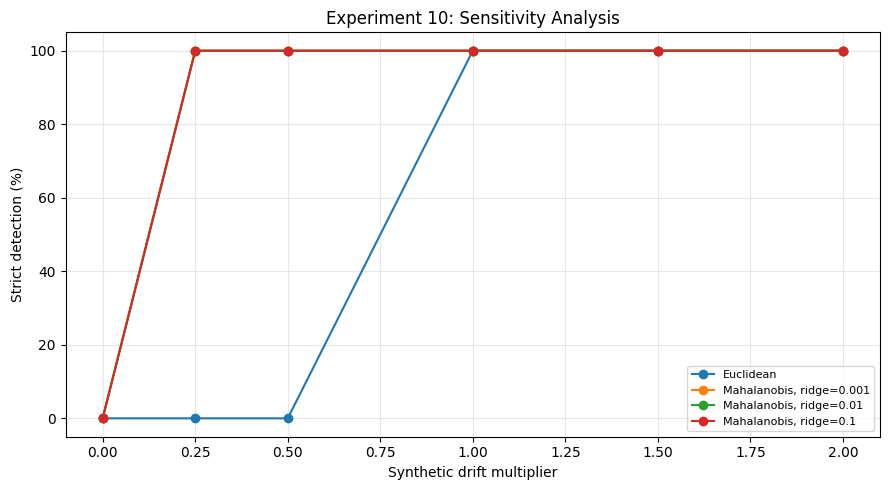

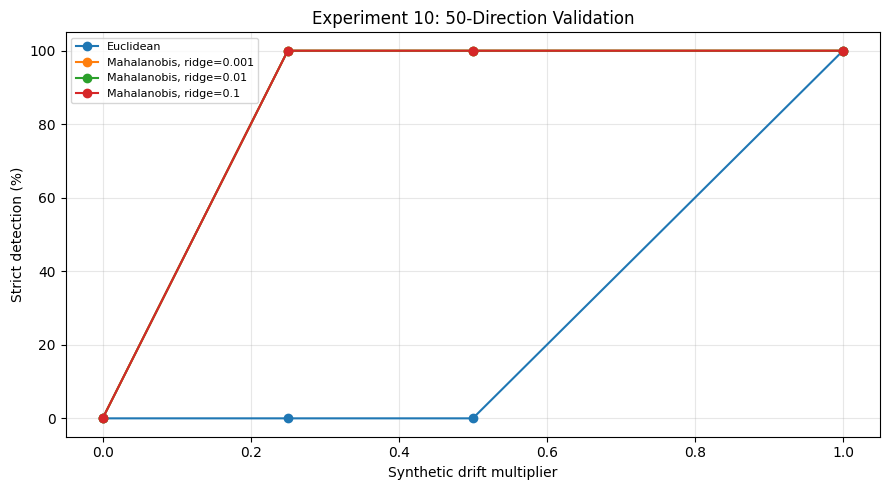

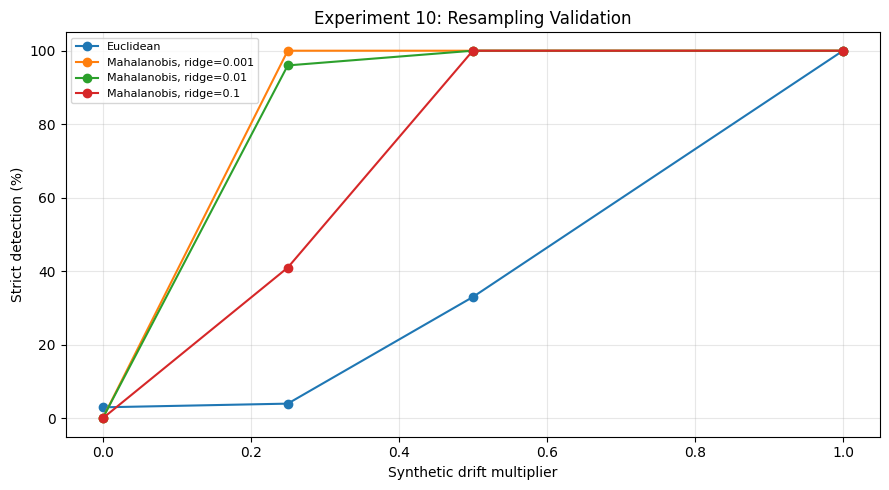

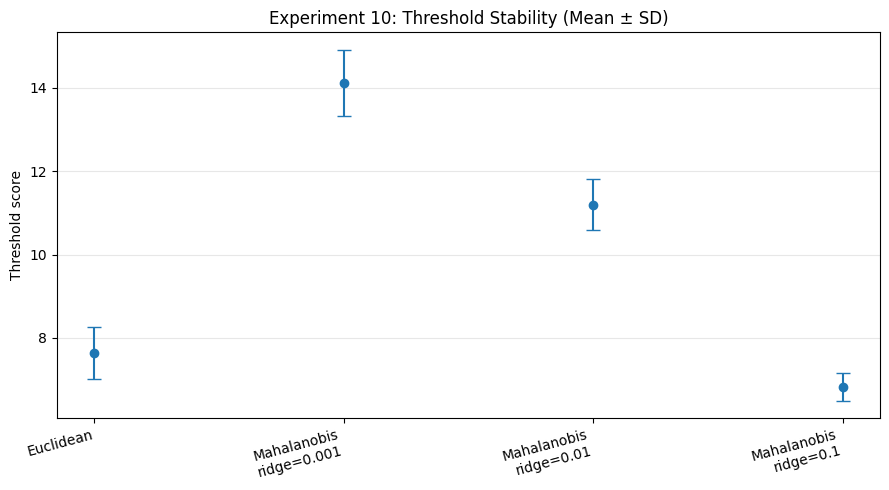

Saved figures to: /content/experiment10_final_figures
Files: ['figure1_sensitivity.png', 'figure2_direction_validation.png', 'figure3_resampling.png', 'figure4_threshold_stability.png']


In [21]:

# Experiment 10 — final report figures
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("experiment10_final_figures")
OUT.mkdir(exist_ok=True)

# Load existing results
sensitivity = pd.read_csv("experiment10_sensitivity_results.csv")
validation = pd.read_csv("experiment10_50_direction_validation.csv")
resampling = pd.read_csv("experiment10_resampling_summary.csv")
thresholds = pd.read_csv("experiment10_threshold_stability_summary.csv")

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(OUT / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

# Figure 1 — Sensitivity analysis
plt.figure(figsize=(9, 5))
for (detector, ridge), group in sensitivity.groupby(
    ["detector", "ridge"], dropna=False
):
    label = detector if pd.isna(ridge) else f"{detector}, ridge={ridge}"
    plt.plot(
        group["drift_multiplier"],
        group["strict_detection_pct"],
        marker="o",
        label=label
    )
plt.xlabel("Synthetic drift multiplier")
plt.ylabel("Strict detection (%)")
plt.title("Experiment 10: Sensitivity Analysis")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
save_plot("figure1_sensitivity.png")

# Figure 2 — 50-direction validation
plt.figure(figsize=(9, 5))
for (detector, ridge), group in validation.groupby(
    ["detector", "ridge"], dropna=False
):
    label = detector if pd.isna(ridge) else f"{detector}, ridge={ridge}"
    plt.plot(
        group["drift_multiplier"],
        group["strict_detection_pct"],
        marker="o",
        label=label
    )
plt.xlabel("Synthetic drift multiplier")
plt.ylabel("Strict detection (%)")
plt.title("Experiment 10: 50-Direction Validation")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
save_plot("figure2_direction_validation.png")

# Figure 3 — Resampling results
rate_column = "strict_detection_pct"
plt.figure(figsize=(9, 5))
for (detector, ridge), group in resampling.groupby(
    ["detector", "ridge"], dropna=False
):
    label = detector if pd.isna(ridge) else f"{detector}, ridge={ridge}"
    plt.plot(
        group["drift_multiplier"],
        group[rate_column],
        marker="o",
        label=label
    )
plt.xlabel("Synthetic drift multiplier")
plt.ylabel("Strict detection (%)")
plt.title("Experiment 10: Resampling Validation")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
save_plot("figure3_resampling.png")

# Figure 4 — Threshold stability
threshold_labels = [
    f"{r.detector}" if pd.isna(r.ridge)
    else f"{r.detector}\nridge={r.ridge}"
    for r in thresholds.itertuples()
]
x = np.arange(len(thresholds))
means = thresholds["mean_threshold"].to_numpy()
stds = thresholds["std_threshold"].to_numpy()

plt.figure(figsize=(9, 5))
plt.errorbar(x, means, yerr=stds, fmt="o", capsize=5)
plt.xticks(x, threshold_labels, rotation=15, ha="right")
plt.ylabel("Threshold score")
plt.title("Experiment 10: Threshold Stability (Mean ± SD)")
plt.grid(True, axis="y", alpha=0.3)
save_plot("figure4_threshold_stability.png")

print("Saved figures to:", OUT.resolve())
print("Files:", sorted(p.name for p in OUT.glob("*.png")))


In [22]:

from pathlib import Path
import zipfile

figure_dir = Path("experiment10_final_figures")
figure_files = sorted(figure_dir.glob("*.png"))

if len(figure_files) != 4:
    print(f"Expected 4 figures, found {len(figure_files)}:")
    print([p.name for p in figure_files])
else:
    zip_path = Path("experiment10_final_figures.zip")
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
        for file in figure_files:
            archive.write(file, arcname=file.name)

    print("Created:", zip_path)
    print("Figures included:")
    for file in figure_files:
        print("-", file.name)

    from google.colab import files
    files.download(str(zip_path))


Created: experiment10_final_figures.zip
Figures included:
- figure1_sensitivity.png
- figure2_direction_validation.png
- figure3_resampling.png
- figure4_threshold_stability.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

import pandas as pd
from google.colab import files

sensitivity = pd.read_csv("experiment10_sensitivity_results.csv")
validation = pd.read_csv("experiment10_50_direction_validation.csv")

sensitivity["result_source"] = "Sensitivity analysis"
validation["result_source"] = "50-direction validation"

columns = [
    "drift_multiplier", "detector", "ridge", "directions",
    "any_alarm_pct", "strict_detection_pct", "post_alarm_pct",
    "result_source"
]

combined = pd.concat(
    [sensitivity[columns], validation[columns]],
    ignore_index=True
)

combined.to_csv("experiment10_combined_comparison.csv", index=False)
files.download("experiment10_combined_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
import pandas as pd
import numpy as np
from google.colab import files

# 1. Recreate the threshold audit from the original calibration scores
audit_rows = []

for (name, ridge), model in detectors.items():
    if name == "Euclidean":
        scores = euclidean_scores(
            W_calibration, model["center"]
        )
    else:
        scores = mahalanobis_scores(
            W_calibration,
            model["center"],
            model["inverse_covariance"]
        )

    threshold = float(
        np.quantile(scores, CALIBRATION_QUANTILE, method="higher")
    )

    audit_rows.append({
        "detector": name,
        "ridge": ridge,
        "calibration_windows": len(scores),
        "threshold": threshold,
        "scores_above_threshold": int(np.sum(scores > threshold)),
        "scores_equal_threshold": int(np.sum(scores == threshold)),
        "empirical_alarm_rate": float(np.mean(scores > threshold))
    })

threshold_audit = pd.DataFrame(audit_rows)
threshold_audit.to_csv("experiment10_threshold_audit.csv", index=False)

# 2. Recreate threshold stability trials using the same procedure
N_SPLITS = 100
rng = np.random.default_rng(2061)
threshold_rows = []

for split_id in range(N_SPLITS):
    permutation = rng.permutation(len(Z_calibration))
    selected = Z_calibration[permutation]

    n_images = (len(selected) // 2 // WINDOW_SIZE) * WINDOW_SIZE
    calibration_sample = selected[:n_images]

    windows = calibration_sample.reshape(
        -1, WINDOW_SIZE, calibration_sample.shape[1]
    ).mean(axis=1)

    for (name, ridge), model in detectors.items():
        if name == "Euclidean":
            scores = euclidean_scores(windows, model["center"])
        else:
            scores = mahalanobis_scores(
                windows, model["center"], model["inverse_covariance"]
            )

        threshold_rows.append({
            "split_id": split_id,
            "detector": name,
            "ridge": ridge,
            "n_calibration_windows": len(scores),
            "threshold": float(
                np.quantile(scores, CALIBRATION_QUANTILE, method="higher")
            )
        })

threshold_stability = pd.DataFrame(threshold_rows)
threshold_stability.to_csv(
    "experiment10_threshold_stability_trials.csv", index=False
)

print("Threshold audit:")
display(threshold_audit.round(4))

print("\nThreshold stability trials:", len(threshold_stability))
print("Both CSV files have been recreated.")

files.download("experiment10_threshold_audit.csv")
files.download("experiment10_threshold_stability_trials.csv")

Threshold audit:


,detector,ridge,calibration_windows,threshold,scores_above_threshold,scores_equal_threshold,empirical_alarm_rate
0,Euclidean,NaN,30,7.5478,1,1,0.0333
1,Mahalanobis,0.001,30,14.0490,1,1,0.0333
2,Mahalanobis,0.010,30,11.1010,1,1,0.0333
3,Mahalanobis,0.100,30,6.9832,1,1,0.0333



Threshold stability trials: 400
Both CSV files have been recreated.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>